# Analysis for the Project: Debt-Based License Suspension

## The Main Questions:
- What are the reasons for license suspensions? [Jassim]
- What % are not falling under safety related? [Rachel, Alberto]
- What % are debt based? [Sarah]
- How many people lose their license over nothing dangerous? [Yuan, Ethan]

In [129]:
%pip install python-calamine polars numpy pandas -U

Note: you may need to restart the kernel to use updated packages.


In [130]:
import numpy as np
import polars as pl
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

data_path = pathlib.Path().cwd().parent / "data"
img_path = pathlib.Path().cwd().parent / "img"

In [131]:
reinstatement_path = pathlib.Path.cwd().parent.joinpath('data', r'Reinstatement_information_Part_2 (1).xlsx')

reinstatement = pl.from_dataframe(
    pd.concat([
        t1 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=0), 
        t2 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=1).drop(columns=['fi64SanctionKey', 'flngAccountKey']), 
        t3 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=2).drop(columns=['fi64SanctionKey', 'flngAccountKey'])
    ])
)

assert(reinstatement.shape[0] == t1.shape[0] + t2.shape[0] + t3.shape[0])

print(reinstatement.shape)
reinstatement.head()

(148199, 6)


Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
i64,str,str,str,str,str
2020,"""NON-PAYMENT OF…","""Indefinite""","""1072""",null,null
2020,"""PROPERTY DAMAG…","""Indefinite""","""714""",null,null
2020,"""NRVC Withdrawa…","""Indefinite""","""1191""",null,null
2020,"""NRVC Withdrawa…","""Indefinite""","""924""",null,null
2020,"""94C35 __ PRESE…","""Definite""","""365""","""PD_GRA""","""Grafton Police…"


In [132]:
reinstatement.null_count()

Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
u32,u32,u32,u32,u32,u32
0,0,12,0,119770,119770


In [133]:
suspension_path = pathlib.Path.cwd().parent.joinpath('data', r'Suspension_information_Part_1 (1).xlsx')

suspension = pl.from_dataframe(
    pd.concat([
        t1 := pd.read_excel(suspension_path, engine='calamine', sheet_name=0), 
        t2 := pd.read_excel(suspension_path, engine='calamine', sheet_name=1).drop(columns=['fi64SanctionKey', 'Sanction Type']), 
        t3 := pd.read_excel(suspension_path, engine='calamine', sheet_name=2).drop(columns=['fi64SanctionKey', 'Sanction Type'])
    ])
)[['Year', 'Description', 'Term']]

assert(suspension.shape[0] == t1.shape[0] + t2.shape[0] + t3.shape[0])

print(suspension.shape)
suspension.head()

(342783, 3)


Year,Description,Term
i64,str,str
2020,"""Operating Unde…","""Definite"""
2020,"""Operating Unde…","""Definite"""
2020,"""Operating Unde…","""Definite"""
2020,"""Ignition Inter…","""Indefinite"""
2020,"""Operating Unde…","""Definite"""


In [134]:
sus_by_year = suspension.to_pandas().groupby(['Year', 'Description']).size()
pd.DataFrame(sus_by_year)

0
Year Description                                           
2020 A20 - DUI of alcohol or drugs                        1
     A60 - Underage DUI BAC >=.02                         6
     A61 - Unge Admin DUI BAC >=.02                      12
     ADMIN PER SE                                      2802
     B01 - Hit & run after accident                       8
...                                                     ...
2022 USE MV WITHOUT AUTHORITY c90 §24(2)(a)             123
     USE MV WITHOUT AUTHORITY, 2ND OFF. c90 §24(2)(a)     7
     USE MV WITHOUT AUTHORITY, 3RD OFF. c90 §24(2)(a)     2
     VANDALIZE PROPERTY c266 §126A                        6
     Youth Alcohol Program Suspension                   195

[396 rows x 1 columns]

In [135]:
cur_suspended_path = pathlib.Path.cwd().parent.joinpath('data', r'Currently_Suspended_information_Part_3_as_of_12082_022 (1).xlsx')
cur_suspended = pl.read_excel(cur_suspended_path, engine='calamine')
print(cur_suspended.shape)
cur_suspended.head()

(693100, 5)


Description,Term,Days Sus/Rev,Authority,Issuing Agency
str,str,str,null,null
"""COURT DEFAULT""","""Indefinite""","""INDEFINITE""",null,null
"""W00 - Non-ACD …","""Indefinite""","""INDEFINITE""",null,null
"""Ignition Inter…","""Indefinite""","""INDEFINITE""",null,null
"""W00 - Non-ACD …","""Indefinite""","""INDEFINITE""",null,null
"""FSU __ 5 SURCH…","""Indefinite""","""INDEFINITE""",null,null


Description
PAYMENT DEFAULT                94842
Major Disqualification         89586
Three Surchargeable Events     78437
WARRANT                        56358
COURT DEFAULT                  50451
Other                         323426
dtype: int64

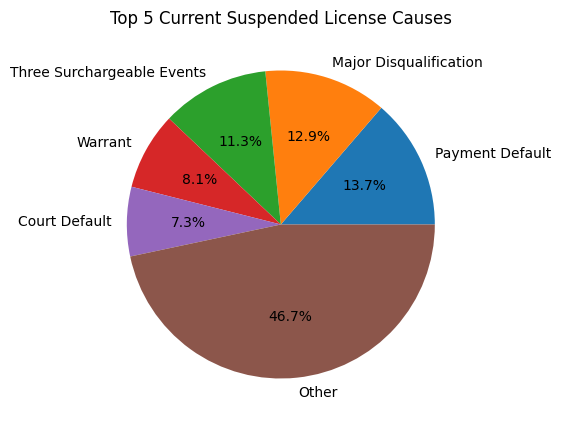

In [147]:
top_num = 5
cur_grouped_sorted = cur_suspended.to_pandas().groupby('Description').size().sort_values(ascending=False)
cur_grouped = cur_grouped_sorted[:top_num]
cur_grouped['Other'] = cur_grouped_sorted[top_num:].sum()

display(cur_grouped)

plt.figure(figsize=(5, 5))
plt.title(f'Top {top_num} Current Suspended License Causes')
plt.pie(cur_grouped, labels=[i.title() for i in cur_grouped.index], autopct='%1.1f%%')
plt.savefig(img_path / f'top_{top_num}_suspended_license_causes.png')
plt.show()

In [137]:
default = pl.from_dataframe(cur_suspended).filter((pl.col("Description") == "PAYMENT DEFAULT") & (pl.col("Term") == "Indefinite"))
print(f'{default.shape[0]} suspensions due to payment default, {round(default.shape[0]/cur_suspended.shape[0]*100, 3)}% of {cur_suspended.shape[0]} total suspensions')

94841 suspensions due to payment default, 13.684% of 693100 total suspensions


In [138]:
len(np.unique(cur_suspended['Description'].to_list() + reinstatement['Sanction Description'].to_list()))

197

In [139]:
reasons_path = pathlib.Path.cwd().parent.joinpath('data', 'suspension_reasons_classified.csv')

reasons = pl.read_csv(reasons_path)[['Description', 'dangerous', 'debt_based']]
reasons

Description,dangerous,debt_based
str,bool,bool
"""PAYMENT DEFAUL…",false,true
"""Three Surcharg…",false,false
"""Major Disquali…",true,false
"""Reciprocal Sus…",false,false
"""WARRANT""",false,false
…,…,…
"""RDR __ RESUSP …",false,false
"""CHEMICAL TEST …",false,false
"""CHEAT ON CDL E…",false,false


In [140]:
sus_reason = suspension.join(reasons, on='Description')
sus_reason

Year,Description,Term,dangerous,debt_based
i64,str,str,bool,bool
2020,"""Operating Unde…","""Definite""",true,false
2020,"""Operating Unde…","""Definite""",true,false
2020,"""Operating Unde…","""Definite""",true,false
2020,"""Ignition Inter…","""Indefinite""",true,false
2020,"""Operating Unde…","""Definite""",true,false
…,…,…,…,…
2022,"""COMPLAINT REGU…","""Indefinite""",false,false
2022,"""Operating Unde…","""Definite""",true,false
2022,"""Operating Unde…","""Definite""",true,false


In [141]:
dd_by_year = sus_reason.group_by('Year').agg(
    pl.col('Description').count().alias('total_count'),
    pl.col('dangerous').sum().alias('dangerous_count'),
    pl.col('debt_based').sum().alias('debt_based_count'),
    (pl.col('dangerous').sum()/pl.count('Description')*100).alias('dangerous_percentage'), 
    (pl.col('debt_based').sum()/pl.count('Description')*100).alias('debt_based_percentage'),
).sort('Year')
dd_by_year

Year,total_count,dangerous_count,debt_based_count,dangerous_percentage,debt_based_percentage
i64,u32,u32,u32,f64,f64
2020,116841,55120,21142,47.175221,18.094676
2021,111342,47738,20052,42.875106,18.009377
2022,114600,46461,23160,40.541885,20.209424


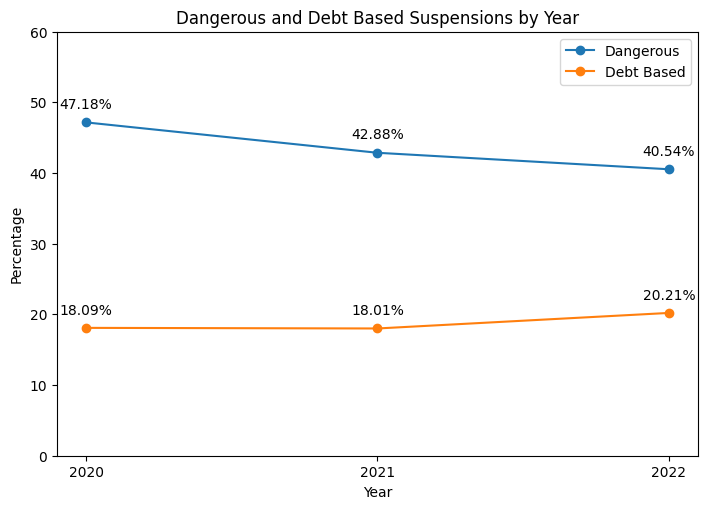

In [148]:
plt.figure(figsize=(7, 5))
plt.title('Dangerous and Debt Based Suspensions by Year')

plt.plot(dd_by_year['Year'], dd_by_year['dangerous_percentage'], label='Dangerous', marker='o')
plt.plot(dd_by_year['Year'], dd_by_year['debt_based_percentage'], label='Debt Based', marker='o')

plt.xticks(dd_by_year['Year'])

for i, v in zip(dd_by_year['Year'], dd_by_year['dangerous_percentage']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v in zip(dd_by_year['Year'], dd_by_year['debt_based_percentage']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
    )

plt.tight_layout()
plt.ylim(0, 60)

plt.xlabel('Year')
plt.ylabel('Percentage')

plt.savefig(img_path / 'dangerous_debt_based_suspensions_by_year.png')
plt.legend()
plt.show()

In [143]:
hypothesis_table = sus_reason.filter((pl.col('dangerous') != True)& pl.col('debt_based'))
hypothesis_table

Year,Description,Term,dangerous,debt_based
i64,str,str,bool,bool
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
…,…,…,…,…
2022,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2022,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2022,"""PAYMENT DEFAUL…","""Indefinite""",false,true


In [144]:
hypo_group = hypothesis_table.group_by('Year').agg(
    (pl.col('Description').count()/dd_by_year['total_count']*100).alias('Count'),
).sort('Year')
hypo_group

Year,Count
i64,f64
2020,18.988342
2021,17.497382
2022,19.821809


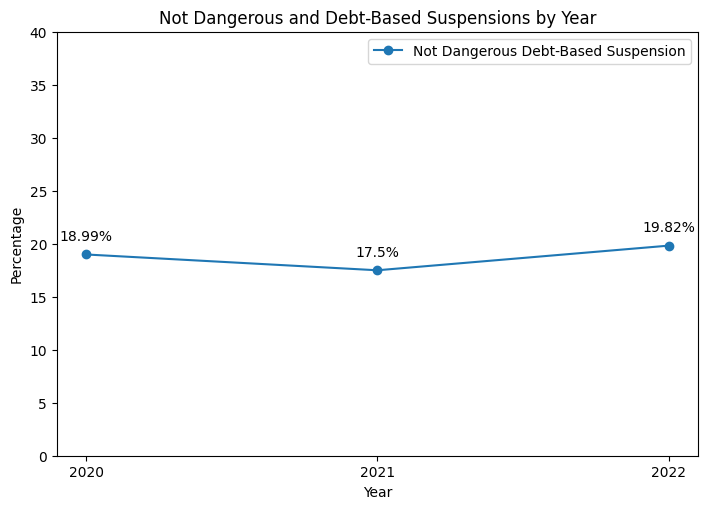

In [149]:
plt.figure(figsize=(7, 5))
plt.title('Not Dangerous and Debt-Based Suspensions by Year')

plt.plot(hypo_group['Year'], hypo_group['Count'], label='Not Dangerous Debt-Based Suspension', marker='o')

plt.xticks(hypo_group['Year'])

for i, v in zip(hypo_group['Year'], hypo_group['Count']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )


plt.ylim(0, 40)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Percentage')

plt.savefig(img_path / 'not_dangerous_debt_based_suspensions_by_year.png')
plt.legend()
plt.show()

In [146]:
temp = cur_suspended['Description'].extend(suspension['Description']).extend(reinstatement['Sanction Description'])

# to prevent constant rewrites
if not pathlib.Path.exists(data_path.joinpath('suspension_reasons.csv')):
    temp.value_counts().sort('count', descending=True).to_pandas().to_csv(data_path.joinpath('suspension_reasons.csv'), index=False)